<a href="https://colab.research.google.com/github/lakshuu-jay/Projects/blob/main/SupervisedVS_Unsupervised.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<class 'pandas.core.frame.DataFrame'>
Index: 5000 entries, 79545.45857431678 to 65510.581803666224
Data columns (total 6 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Avg. Area House Age           5000 non-null   float64
 1   Avg. Area Number of Rooms     5000 non-null   float64
 2   Avg. Area Number of Bedrooms  5000 non-null   float64
 3   Area Population               5000 non-null   float64
 4   Price                         5000 non-null   float64
 5   Address                       5000 non-null   object 
dtypes: float64(5), object(1)
memory usage: 273.4+ KB


/tmp/ipykernel_497/3187293409.py:14: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['Price'])


-1118638.0020791441


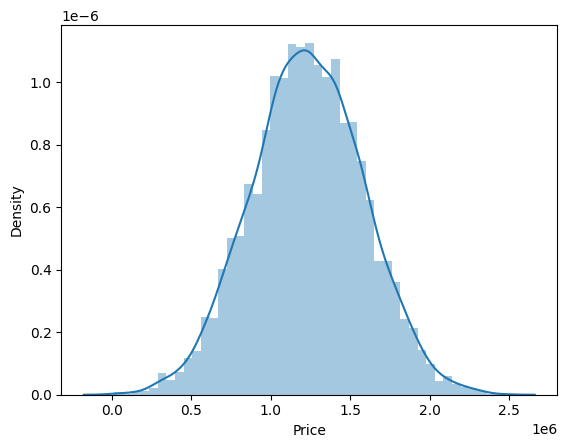

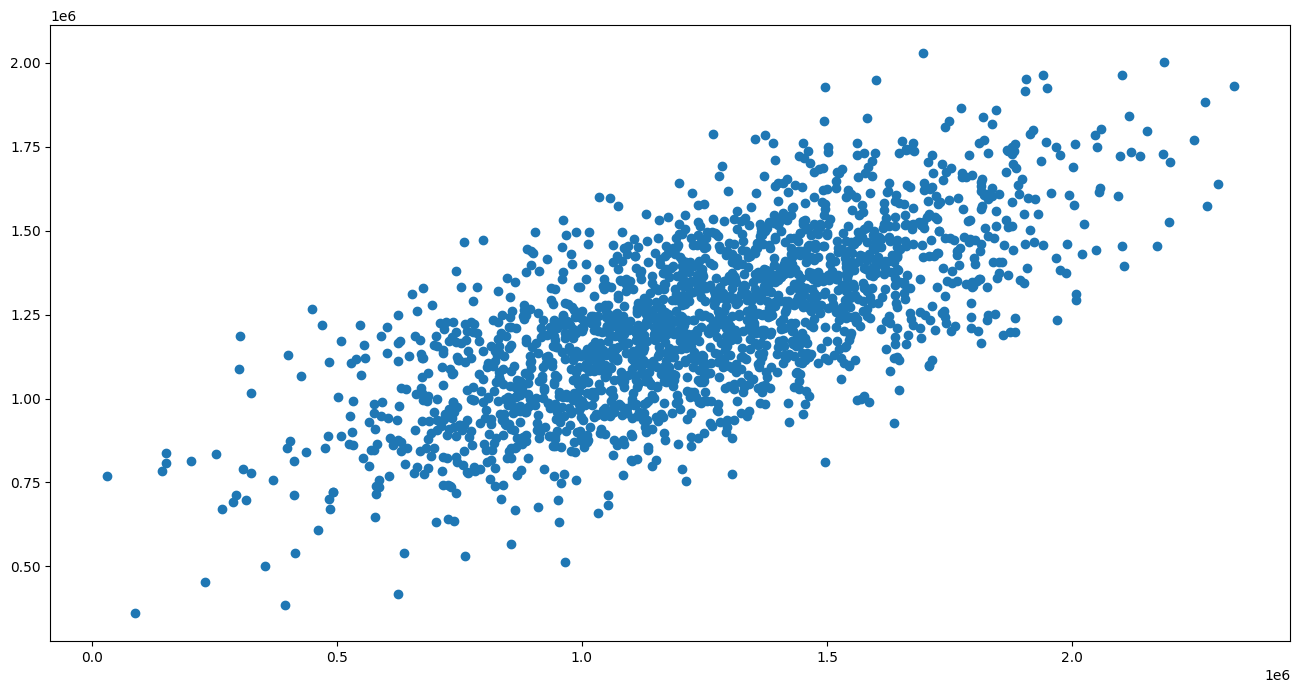

/tmp/ipykernel_497/3187293409.py:38: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot((y_test-predictions),bins=50)


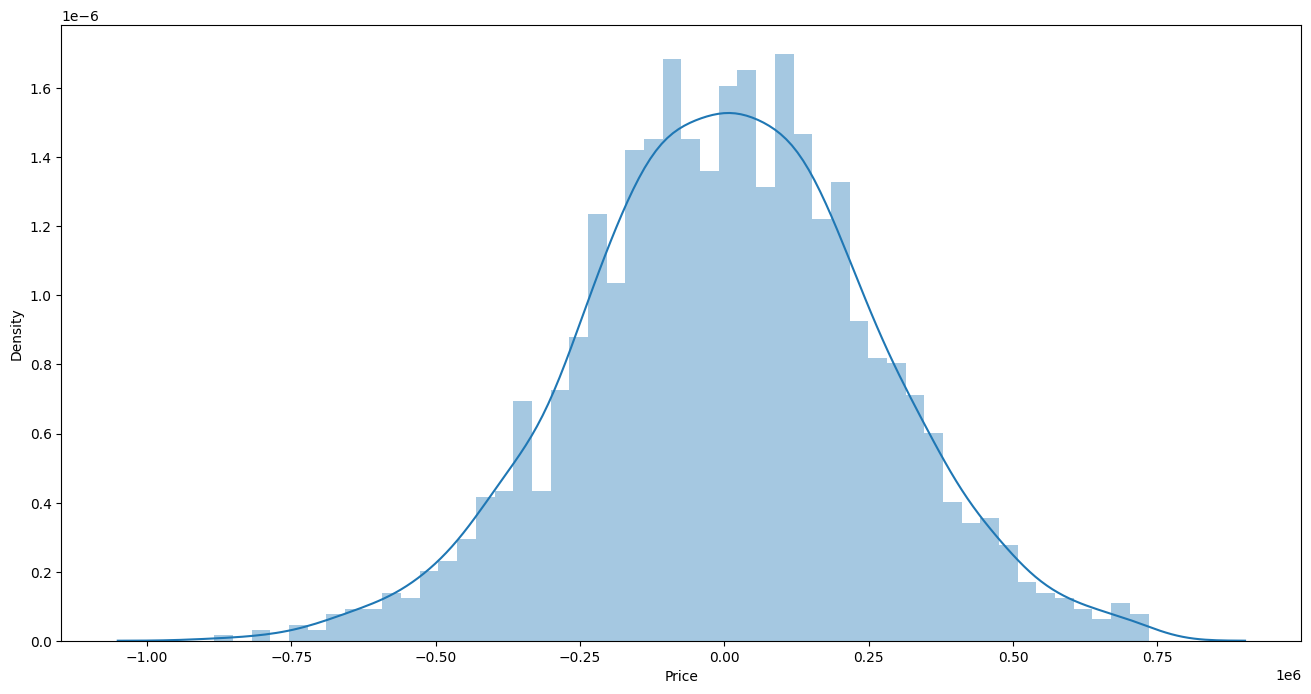

MAE: 202189.43869512956
MSE: 64936834445.32556
RMSE: 254827.0677250075


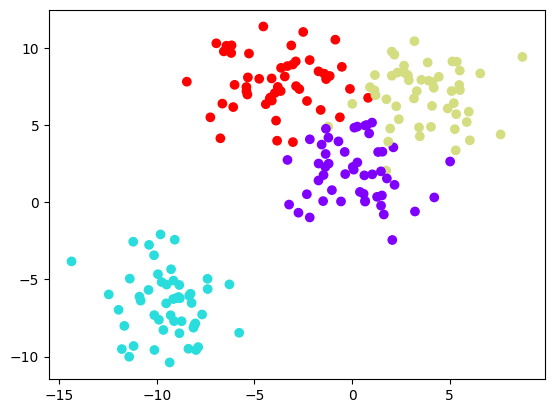

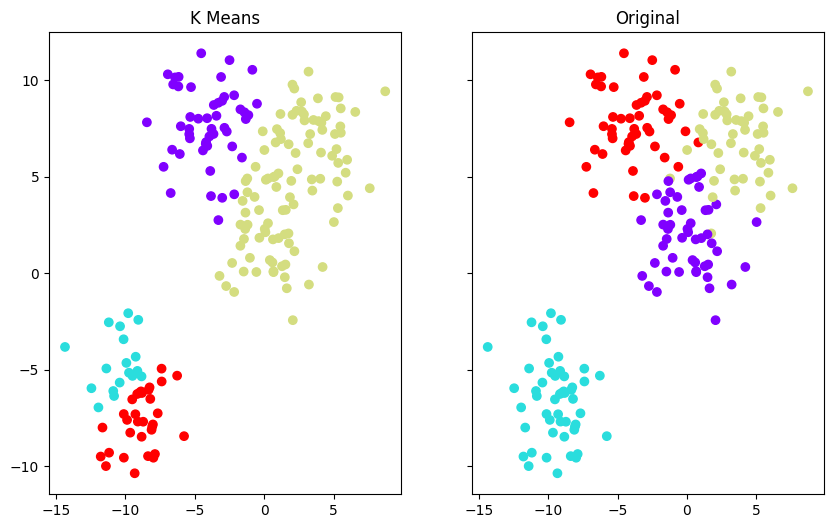

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

df = pd.read_csv('USA_Housing.csv', index_col=0)
df.head()

df.info()

df.describe()

sns.distplot(df['Price'])

x=df[['Avg. Area House Age', 'Avg. Area Number of Rooms', 'Avg. Area Number of Bedrooms', 'Area Population']]
y=df['Price']

from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test=train_test_split(x, y, test_size=0.4, random_state=101)

from sklearn.linear_model import LinearRegression
lm=LinearRegression()
lm.fit(x_train, y_train)

print(lm.intercept_)

cdf=pd.DataFrame(lm.coef_, x.columns, columns=['Coeff'])
cdf

predictions=lm.predict(x_test)

plt.figure(figsize=(16,8))
plt.scatter(y_test,predictions)
plt.show()

plt.figure(figsize=(16,8))
sns.distplot((y_test-predictions),bins=50)
plt.show()

from sklearn import metrics
print('MAE:', metrics.mean_absolute_error(y_test, predictions))
print('MSE:', metrics.mean_squared_error(y_test, predictions))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_test, predictions)))

from sklearn.datasets import make_blobs

data = make_blobs(n_samples=200, n_features=2,
centers=4, cluster_std=1.8, random_state=101)

plt.scatter(data[0][:,0],data[0][:,1],c=data[1],cmap='rainbow')

from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=4)
kmeans.fit(data[0])

kmeans.cluster_centers_

kmeans.labels_

f, (ax1, ax2) = plt.subplots(1, 2, sharey=True, figsize=(10,6))
ax1.set_title('K Means')
ax1.scatter(data[0][:,0],data[0][:,1],c=kmeans.labels_,cmap='rainbow')
ax2.set_title("Original")
ax2.scatter(data[0][:,0],data[0][:,1],c=data[1],cmap='rainbow')